In [1]:
import sys

print(sys.executable)

c:\Users\Eka\OneDrive\Documents\LnT_ML_FinalProject\venv\Scripts\python.exe


In [2]:
import sqlite3
import pandas as pd

1. Problem Statement & Objectives
menggunakan 2 Model:
- Model 1 - Regression: Predict sales.
- Model 2 — Classification: Predict whether a transaction is profitable.


2. Database Connection & Data Loading

import library dibawah berfungsi untuk:
- menghubungkan database dengan sqlite3 
- manipulasi data dengan pandas    
- perhitungan dengan numpy 

In [4]:
import sqlite3
import pandas as pd
import numpy as np

Database diakses langsung menggunakan sqlite3 dari Python menggunakan library sqlite3 yang sudah diimport sebelumnya

In [5]:
conn = sqlite3.connect("../superstore.sqlite")

print("Database connection successful!")

Database connection successful!


Dilakukan pengecekan data dilakukan dari superstore.sqlite yang sudah ada di folder, terlebih dahulu di run untuk membaca tabelnya

In [9]:
tables = pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type = 'table';
""", conn)

tables

,name
0,dim_customers
1,dim_products
2,dim_product_name_variants
3,dim_locations
4,orders
5,order_items


Lalu tiap table di inspect untuk melihat kolom dan komponen yang ada pada tiap tabel.


In [10]:
for table in tables["name"]:
    print(f"\n--- {table} ---")
    
    columns = pd.read_sql_query(
        f"PRAGMA table_info({table});",
        conn
    )
    
    display(columns[["name", "type"]])
    


--- dim_customers ---


,name,type
0,customer_id,TEXT
1,customer_name,TEXT
2,segment,TEXT



--- dim_products ---


,name,type
0,product_id,TEXT
1,category,TEXT
2,sub_category,TEXT
3,product_name,TEXT



--- dim_product_name_variants ---


...

,name,type
0,location_id,INTEGER
1,city,TEXT
2,state,TEXT
3,country,TEXT
4,region,TEXT
5,market,TEXT
6,market2,TEXT



--- orders ---


,name,type
0,order_key,TEXT
1,order_id_raw,TEXT
2,customer_id,TEXT
3,order_date,TEXT
4,ship_date,TEXT
5,ship_mode,TEXT
6,order_priority,TEXT
7,location_id,INTEGER



--- order_items ---


,name,type
0,row_id,INTEGER
1,order_key,TEXT
2,product_id,TEXT
3,discount,REAL
4,quantity,INTEGER
5,sales,REAL
6,profit,REAL
7,shipping_cost,REAL
8,year,INTEGER
9,week_num,INTEGER


Tabel-tabel data SQL sudah dipisahkan, akan digunakan "JOIN" untuk menghubungkan informasi-informasi berupa order, customer, location, dan product information 

In [11]:
query = """
SELECT
    oi.row_id,
    oi.order_key,
    oi.product_id,
    oi.discount,
    oi.quantity,
    oi.sales,
    oi.profit,
    oi.shipping_cost,
    oi.year,
    oi.week_num,

    o.customer_id,
    o.order_date,
    o.ship_date,
    o.ship_mode,
    o.order_priority,
    o.location_id,

    c.customer_name,
    c.segment,

    l.city,
    l.state,
    l.country,
    l.region,
    l.market,

    p.category,
    p.sub_category,
    p.product_name

FROM order_items oi

JOIN orders o
    ON oi.order_key = o.order_key

JOIN dim_customers c
    ON o.customer_id = c.customer_id

JOIN dim_locations l
    ON o.location_id = l.location_id

JOIN dim_products p
    ON oi.product_id = p.product_id
"""

In [12]:
df = pd.read_sql_query(query, conn)

print("Dataset successfully loaded!")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Dataset successfully loaded!
Rows: 51,290
Columns: 26


In [13]:
df.head()

,row_id,order_key,product_id,discount,quantity,sales,profit,shipping_cost,year,week_num,...,customer_name,segment,city,state,country,region,market,category,sub_category,product_name
0,1,MX-2014-143658_SC-205753,OFF-LA-10002782,0.0,3,13.0,4.56,1.033,2014,40,...,Sonia Cooley,Consumer,Mexico City,Distrito Federal,Mexico,North,LATAM,Office Supplies,Labels,"Hon File Folder Labels, Adjustable"
1,2,MX-2012-155047_KW-165703,FUR-FU-10004015,0.0,8,252.0,90.72,13.449,2012,42,...,Kelly Williams,Consumer,Dos Quebradas,Risaralda,Colombia,South,LATAM,Furniture,Furnishings,"Tenex Clock, Durable"
2,3,MX-2012-155047_KW-165703,FUR-BO-10002352,0.0,2,193.0,54.08,9.627,2012,42,...,Kelly Williams,Consumer,Dos Quebradas,Risaralda,Colombia,South,LATAM,Furniture,Bookcases,"Ikea 3-Shelf Cabinet, Mobile"
3,4,MX-2012-155047_KW-165703,OFF-BI-10004428,0.0,4,35.0,4.96,1.371,2012,42,...,Kelly Williams,Consumer,Dos Quebradas,Risaralda,Colombia,South,LATAM,Office Supplies,Binders,"Cardinal Binder, Clear"
4,5,MX-2012-155047_KW-165703,OFF-AR-10004594,0.0,2,72.0,11.44,3.787,2012,42,...,Kelly Williams,Consumer,Dos Quebradas,Risaralda,Colombia,South,LATAM,Office Supplies,Art,"Sanford Canvas, Water Color"


In [14]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   row_id          51290 non-null  int64  
 1   order_key       51290 non-null  str    
 2   product_id      51290 non-null  str    
 3   discount        51290 non-null  float64
 4   quantity        51290 non-null  int64  
 5   sales           51290 non-null  float64
 6   profit          51290 non-null  float64
 7   shipping_cost   51290 non-null  float64
 8   year            51290 non-null  int64  
 9   week_num        51290 non-null  int64  
 10  customer_id     51290 non-null  str    
 11  order_date      51290 non-null  str    
 12  ship_date       51290 non-null  str    
 13  ship_mode       51290 non-null  str    
 14  order_priority  51290 non-null  str    
 15  location_id     51290 non-null  int64  
 16  customer_name   51290 non-null  str    
 17  segment         51290 non-null  str    
 1

Bagian Dataset:
Dataset yang sudah berhasil ini menggabungkan informasi berupa order, customer, location, and product

Dataset dicheck / diperiksa untuk membaca tipe data, dan struktur keseluruhannya sebelum dilakukan analisis 

In [15]:
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 51,290
Number of columns: 26


In [16]:
df.columns.tolist()

['row_id',
 'order_key',
 'product_id',
 'discount',
 'quantity',
 'sales',
 'profit',
 'shipping_cost',
 'year',
 'week_num',
 'customer_id',
 'order_date',
 'ship_date',
 'ship_mode',
 'order_priority',
 'location_id',
 'customer_name',
 'segment',
 'city',
 'state',
 'country',
 'region',
 'market',
 'category',
 'sub_category',
 'product_name']

Bagian Analysis Missing Value:
ini untuk memeriksa jika ada nilai yang hilang dari variabel tertentu, nantinya perlu di analysis/diproses ulang

In [17]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0].sort_values(ascending=False)

Series([], dtype: int64)

Bagian Check Duplicate:
untuk check apakah ada yang duplikat dan menjaga agar baris data tidak merusak analisis machine learning nantinya

In [18]:
duplicate_count = df.duplicated().sum()

print(f"Number of duplicated rows: {duplicate_count:,}")

Number of duplicated rows: 0


Bagian fitur Numeric:
fitur berupa statistik deskriptif untuk kita bisa baca distribusi dan skala variabel numeriknya.

In [19]:
df.describe()

,row_id,discount,quantity,sales,profit,shipping_cost,year,week_num,location_id
count,51290.00000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,25645.50000,0.142908,3.476545,246.498440,28.610982,26.375818,2012.777208,31.287112,1712.295652
std,14806.29199,0.212280,2.278766,487.567175,174.340972,57.296810,1.098931,14.429795,1275.144101
min,1.00000,0.000000,1.000000,0.000000,-6599.978000,0.002000,2011.000000,1.000000,1.000000
25%,12823.25000,0.000000,2.000000,31.000000,0.000000,2.610000,2012.000000,20.000000,540.000000
50%,25645.50000,0.000000,3.000000,85.000000,9.240000,7.790000,2013.000000,33.000000,1330.000000
75%,38467.75000,0.200000,5.000000,251.000000,36.810000,24.450000,2014.000000,44.000000,3124.000000
max,51290.00000,0.850000,14.000000,22638.000000,8399.976000,933.570000,2014.000000,53.000000,3819.000000


In [20]:
df[
    ["quantity", "discount", "sales", "profit", "shipping_cost"]
].median()

quantity          3.00
discount          0.00
sales            85.00
profit            9.24
shipping_cost     7.79
dtype: float64

In [21]:
df[
    ["quantity", "discount", "sales", "profit", "shipping_cost"]
].mean()

quantity           3.476545
discount           0.142908
sales            246.498440
profit            28.610982
shipping_cost     26.375818
dtype: float64

Bagian Distribusi Sales:
untuk visualisasi distribusi penjualannya

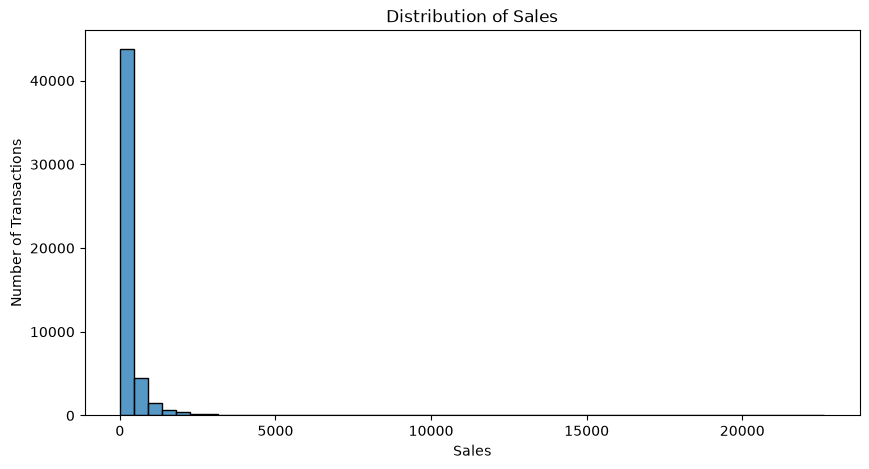

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="sales",
    bins=50
)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Number of Transactions")
plt.show()

Bagian Profit Distribution:
untuk kita bisa melihat kisaran keuntungan nya dan check jika ada yang rugi

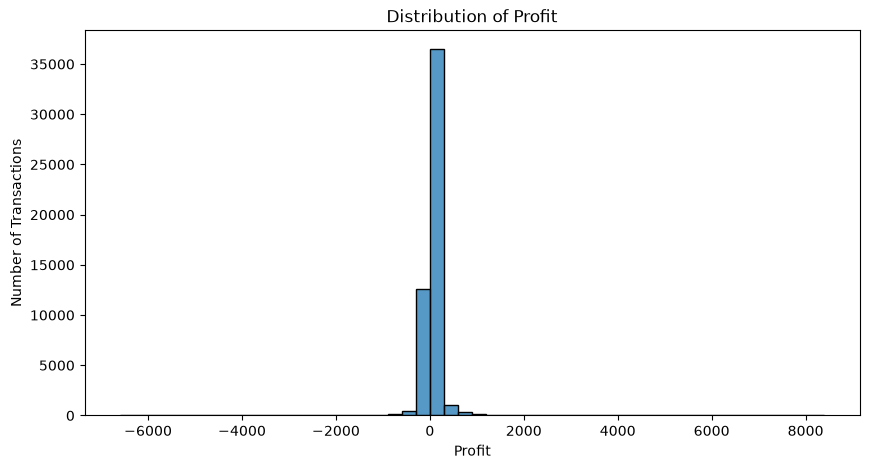

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="profit",
    bins=50
)

plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Number of Transactions")
plt.show()

In [24]:
df["profitable"] = (df["profit"] > 0).astype(int)

In [25]:
df["profitable"].value_counts()

profitable
1    38078
0    13212
Name: count, dtype: int64

In [26]:
df["profitable"].value_counts(normalize=True) * 100

profitable
1    74.240593
0    25.759407
Name: proportion, dtype: float64

Bagian Visualisasi Transaction:
untuk kita bisa check transaksi berdasarkan kategori yang menguntungkan atau merugikan (start dari nol)

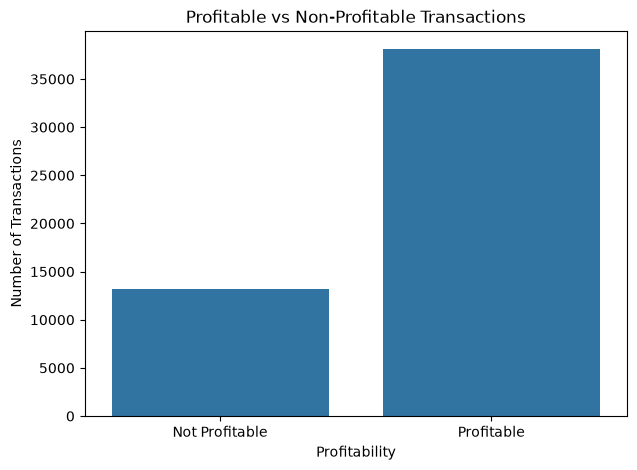

In [27]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="profitable"
)

plt.title("Profitable vs Non-Profitable Transactions")
plt.xlabel("Profitability")
plt.ylabel("Number of Transactions")

plt.xticks(
    [0, 1],
    ["Not Profitable", "Profitable"]
)

plt.show()

Bagian: Sales Categprization:
untuk mengkatogri kan tiap kategori penjualan

In [28]:
category_sales = (
    df.groupby("category")["sales"]
    .sum()
    .sort_values(ascending=False)
)

category_sales

category
Technology         4744691.0
Furniture          4110884.0
Office Supplies    3787330.0
Name: sales, dtype: float64

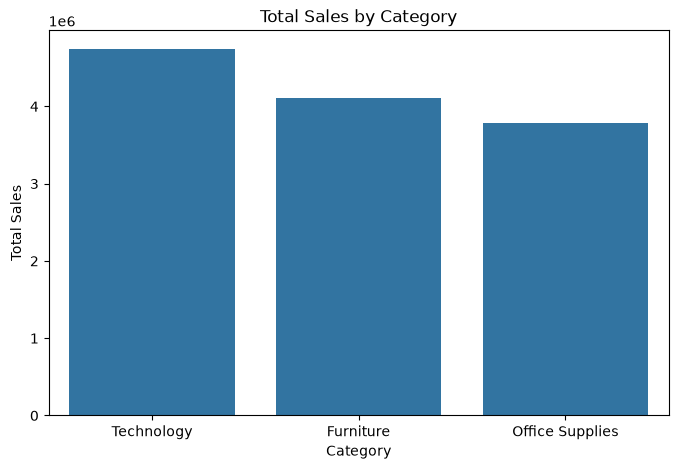

In [29]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.show()

Bagian: Profit Categprization:
untuk mengkatogri kan tiap kategori pemasukan/laba

In [30]:
category_profit = (
    df.groupby("category")["profit"]
    .sum()
    .sort_values(ascending=False)
)

category_profit

category
Technology         663778.73318
Office Supplies    518473.83430
Furniture          285204.72380
Name: profit, dtype: float64

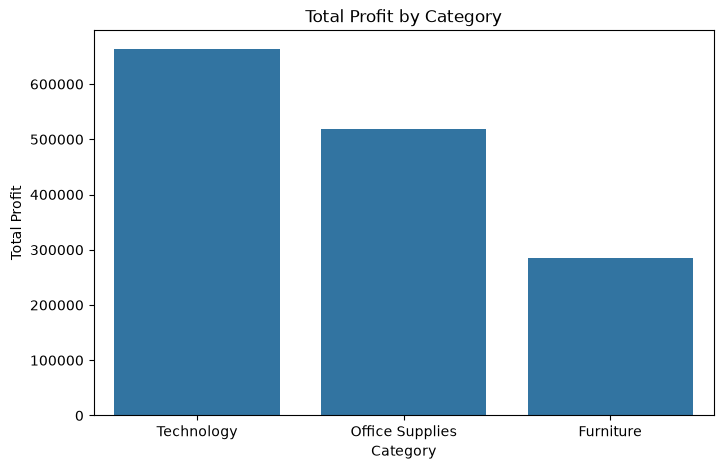

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_profit.index,
    y=category_profit.values
)

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")

plt.show()

Model 1 - Regression


In [32]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [34]:
features = [
    "quantity",
    "discount",
    "shipping_cost",
    "category",
]

X = df[features]
y = df["sales"]

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [36]:
categorical_features = [
    "category",
    "sub_category",
    "segment",
    "ship_mode",
    "region",
    "market"
]

numeric_features = [
    "quantity",
    "discount",
    "shipping_cost",
    "delivery_days"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

regression_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [37]:
regression_model.fit(X_train, y_train)

ValueError: Some column names are not columns of the dataframe: {'market', 'segment', 'sub_category', 'region', 'ship_mode'}

In [38]:
y_pred = regression_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE : {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²  : {r2:.4f}")

NotFittedError: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

Model 2: Classification

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [40]:
df["profitable"] = (df["profit"] > 0).astype(int)

In [41]:
classification_features = [
    "quantity",
    "sales",
    "discount",
    "shipping_cost",
    "category",
]

In [42]:
X = df[classification_features]
y = df["profitable"]

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [44]:
categorical_features = [
    "category",
    "sub_category",
    "segment",
    "ship_mode",
    "region",
    "market"
]

numeric_features = [
    "quantity",
    "sales",
    "discount",
    "shipping_cost",
    "delivery_days"
]

preprocessor_cls = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [45]:
classification_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_cls),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

In [48]:
import joblib

joblib.dump(
    regression_model,
    "../model/regression_model.joblib"
)

joblib.dump(
    classification_model,
    "../model/classification_model.joblib"
)

print("Models saved successfully!")

Models saved successfully!
